# Reading **SRH-2D** meshes with `pyramids-mesh`

**SRH-2D** (Sedimentation and River Hydraulics – 2D) is the USBR / Aquaveo finite-volume river model. A case is described by **three companion files** sharing a base name:

- **`.srhgeom`** — the mesh (nodes + mixed triangular/quadrilateral/polygonal elements),
- **`.srhhydro`** — the control deck (boundary conditions, run settings),
- **`.srhmat`** — the material / roughness zones.

`pyramids-mesh` registers an `srh2d` driver keyed on the `.srhgeom` file; it reads the geometry and pulls the roughness from the sibling `.srhmat` automatically, returning one `UgridDataset`.

The bundled case is the public-domain **USACE HEC-RAS "Muncie"** example (via `psu-efd/pyHMT2D`): ~19,400 mixed elements over ~21,500 nodes, in **feet**. A real mesh — so the maps and the clip actually show something.

## 3. Locate the data

The SRH-2D files live in their own `examples/data/srh2d/` subfolder. We point the driver at `Muncie.srhgeom`; it finds the `.srhmat` sibling itself. (See the folder's `SOURCE.txt` for provenance.)

In [1]:
from pathlib import Path
DATA = Path("../../examples/data")
SRH = DATA / "srh2d"
print(sorted(p.name for p in SRH.glob("Muncie.*")))
print((SRH / "Muncie.srhgeom").resolve())

['Muncie.srhgeom', 'Muncie.srhhydro', 'Muncie.srhmat']
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\examples\data\srh2d\Muncie.srhgeom


## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pyramids.netcdf.ugrid import UgridDataset
import numpy as np
import matplotlib.pyplot as plt

## 4. Read the file

We pass the `.srhgeom` path; the driver reads the geometry and merges the `manning_n` field from the companion `.srhmat`. A driver's only job is to parse the file and hand back a `UgridDataset`. We pass a `pathlib.Path` (never a `str`) and name the `driver` explicitly:

In [3]:
ds = UgridDataset.read_file(SRH / "Muncie.srhgeom", driver="srh2d")
ds

UgridDataset(mesh='mesh2d', n_node=21520, n_face=19407, n_edge=0, variables=['material', 'manning_n', 'node_z'])

In [4]:
# reading switches matplotlib to Agg for headless safety; let cleopatra
# pick the notebook backend (inline) so the plots below embed
from cleopatra.config import Config
Config.set_matplotlib_backend()

'inline'

## 5. Explore the dataset

A `UgridDataset` exposes the mesh size, its coordinate reference system, and the data variables carried alongside the topology. `None` for `crs`/`epsg` simply means the source file declared no projection — the geometry is still valid, it is just unlocated in world space.

In [5]:
print('nodes :', ds.n_node)
print('faces :', ds.n_face)
print('crs   :', ds.crs)
print('epsg  :', ds.epsg)
print('vars  :', ds.data_variable_names)
print('bounds:', ds.bounds)

nodes : 21520
faces : 19407
crs   : None
epsg  : None
vars  : ['material', 'manning_n', 'node_z']
bounds: (402979.635753139, 1799461.01054572, 414645.029795507, 1807466.91484153)


### Per-variable summary

`ds.summary()` returns a pandas `DataFrame` — one row per data variable with count, min, max, mean and standard deviation. A `std` of 0 means that variable is uniform across the mesh.

In [6]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
material,19407,2.00000,7.00000,4.884062,1.615723
manning_n,19407,0.03000,0.06000,0.049040,0.008832
node_z,21520,913.78125,974.84375,943.094422,9.414194


### Global attributes

Each driver stamps provenance into `global_attributes` so you can trace a dataset back to the format it came from after it has been converted.

In [7]:
ds.global_attributes

{'source': 'SRH-2D geometry', 'grid_unit': 'Feet'}

Three variables arrive: `material` and `manning_n` (per element, from the `.srhmat`) and `node_z` (bed elevation, per node). The `grid_unit` global attribute records that coordinates are in **feet**, and the `bounds` are real projected easting/northing — though no CRS/EPSG is embedded, so `crs` is `None`.

## 6. The `Mesh2d` geometry

`ds.mesh` is a `Mesh2d`: node coordinates plus the face-node connectivity table. `face_node_connectivity.data` has shape `(n_face, k)` — row *i* lists the node indices of face *i* (padded for mixed element types). We also derive per-face areas and centroids from that topology.

In [8]:
m = ds.mesh
print('node_x shape           :', np.asarray(m.node_x).shape)
print('connectivity shape     :', np.asarray(m.face_node_connectivity.data).shape)
print('face_areas shape       :', np.asarray(m.face_areas).shape)
centroids = np.asarray(m.face_centroids)  # shape (2, n_face)
print('face_centroids shape   :', centroids.shape)
print('first face areas       :', np.asarray(m.face_areas)[:3])

node_x shape           : (21520,)
connectivity shape     : (19407, 8)
face_areas shape       : (19407,)
face_centroids shape   : (2, 19407)
first face areas       : [5916.8223877  4003.14862061 3178.0559082 ]


The connectivity width above is **8**, not 3: SRH-2D meshes mix triangles, quads and higher-order polygons, and the table is padded to the widest element. This is why a few triangle-only operations (below) do not apply.

## 7. Wireframe — the mesh skeleton

`plot_outline()` draws the bare mesh: every face edge, no data coloring. This is the fastest way to eyeball connectivity, element shapes and the overall extent.

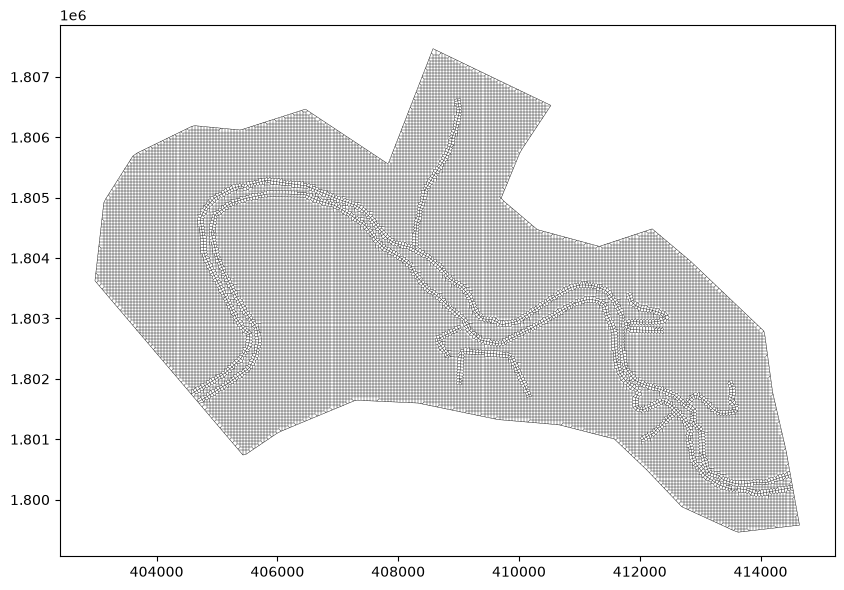

In [9]:
ds.plot_outline()


## 8. A data map

The headline field for a river model is **Manning's n** — the bed roughness, per element, read from the `.srhmat`. We map it. Distinct bands appear: the channel, banks and floodplain each carry a different roughness, exactly the zoning SRH-2D solves against.

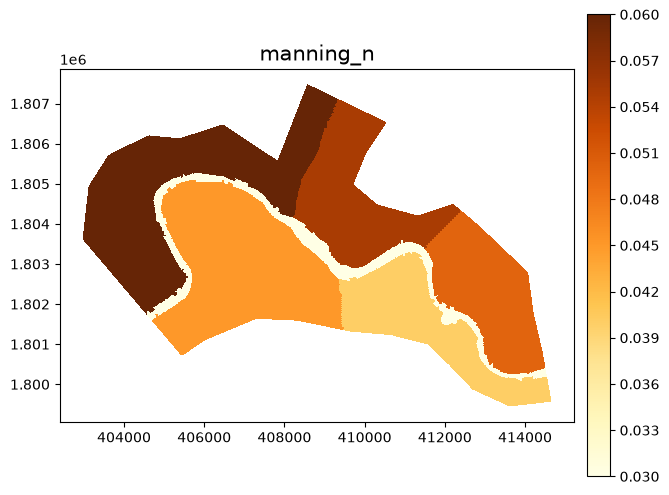

In [10]:
ds.plot('manning_n', cmap='YlOrBr', colorbar=True, title='manning_n')


### A second map — bed elevation (`node_z`)

`node_z` is the terrain the flow runs over. Mapping it shows the valley form — the low channel threading through higher ground.

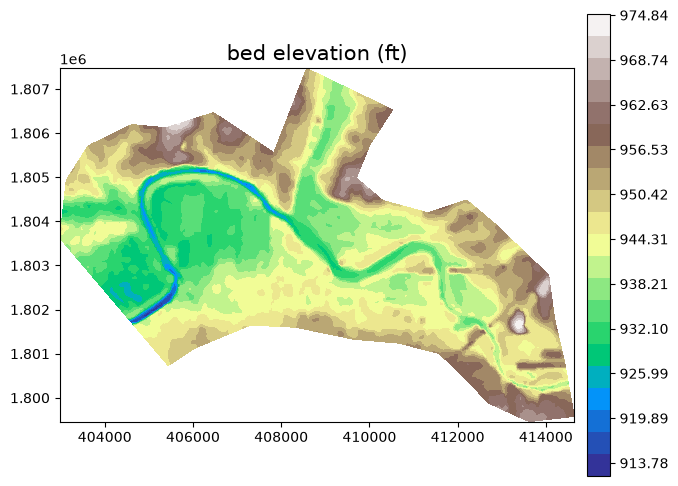

In [11]:
ds.plot("node_z", cmap="terrain", colorbar=True, title="bed elevation (ft)")


## 9. GIS operations

Because a `UgridDataset` is a first-class `pyramids` object, the full geospatial toolkit works on it directly — no conversion step. Below are several operations, each visualised or interpreted. (Operations that need a source CRS, such as `to_crs`, are skipped here: this sample declares none.)

### 9a. Faces as polygons — `to_geodataframe()`

Every face becomes a shapely polygon in a GeoPandas `GeoDataFrame`, ready for a spatial join, an overlay, or export to any OGR vector format.

In [12]:
gdf = ds.to_geodataframe()
gdf.head()

,geometry
0,"POLYGON ((408549.798 1807396.752, 408579.636 1..."
1,"POLYGON ((408629.636 1807441.654, 408629.636 1..."
2,"POLYGON ((408579.636 1807316.915, 408579.636 1..."
3,"POLYGON ((408629.636 1807366.915, 408579.636 1..."
4,"POLYGON ((408679.636 1807366.915, 408629.636 1..."


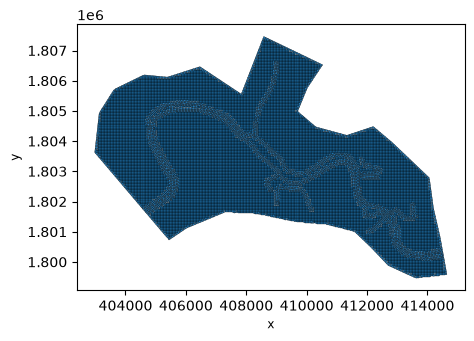

In [13]:
gdf.plot(edgecolor="k", linewidth=0.2, figsize=(5, 4))
plt.gca().set_aspect("equal")


The polygon mosaic is the mesh itself — each cell is now an independent vector feature. That is the bridge from a solver mesh to standard GIS.

### 9b. Outer boundary — `bounding_polygon()` and `exterior_edges()`

`bounding_polygon()` dissolves the faces into a single shapely polygon tracing the mesh outline, and `exterior_edges()` returns the indices of the mesh edges that lie on that boundary — their count is the boundary's edge length.

boundary edges: 629


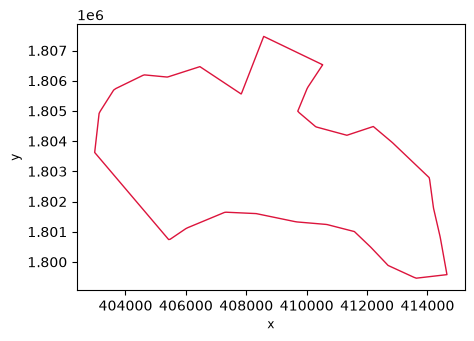

In [14]:
poly = ds.bounding_polygon()
n_boundary = len(ds.exterior_edges())
print('boundary edges:', n_boundary)
import geopandas as gpd
gpd.GeoSeries([poly]).plot(facecolor="none", edgecolor="crimson", figsize=(5, 4))
plt.gca().set_aspect("equal")


The crimson ring is the domain outline; `exterior_edges()` tells us how many element edges trace it — the rest of the edges are interior.

### 9c. Connectivity — `connected_components()`

`connected_components()` labels each face by the connected sub-mesh it belongs to. One unique label means the mesh is a single watertight piece; more than one would reveal detached islands. We attach the labels as a face variable and map them.

faces: 19407  components: 1


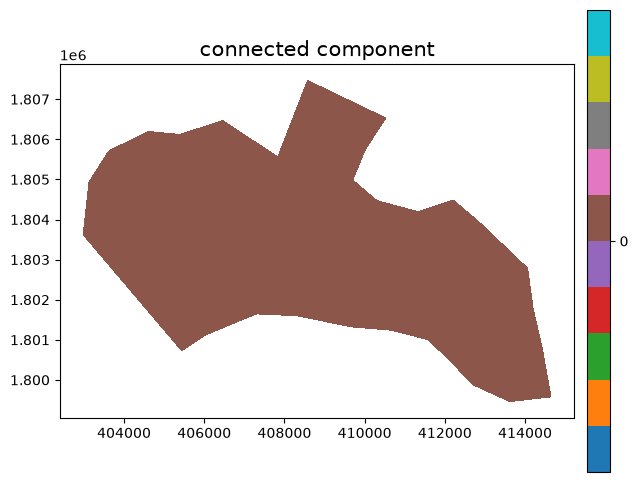

In [15]:
comp = np.asarray(ds.connected_components())
print('faces:', comp.size, ' components:', len(np.unique(comp)))
dc = ds.with_variable("component", comp.astype(float), location="face")
dc.plot("component", cmap="tab10", colorbar=True, title="connected component")


### 9d. Face adjacency — `sparse_adjacency()`

`sparse_adjacency()` returns the face-to-face adjacency as a SciPy sparse matrix (two faces share an edge). For a mesh this large we report its size and non-zero count rather than plotting the pattern — `nnz` is the number of face-neighbour links in the dual graph.

In [16]:
adj = ds.sparse_adjacency()
print('shape:', adj.shape, ' nnz:', adj.nnz)

shape: (19407, 19407)  nnz: 80594


### 9e. Triangle circumcenters — not applicable

`circumcenters()` is defined only for purely triangular meshes. This mesh contains quads and higher-order polygons, so `circumcenters()` raises `ValueError: circumcenters is only defined for triangular meshes.` — we skip it rather than force a triangulation.

### 9f. Clip to a sub-region — `crop()`

`crop(bbox=...)` extracts a sub-mesh inside a bounding box — essential on a mesh this size. We clip to the lower-left quadrant of the extent and plot just that piece.

faces after crop: 4092 of 19407


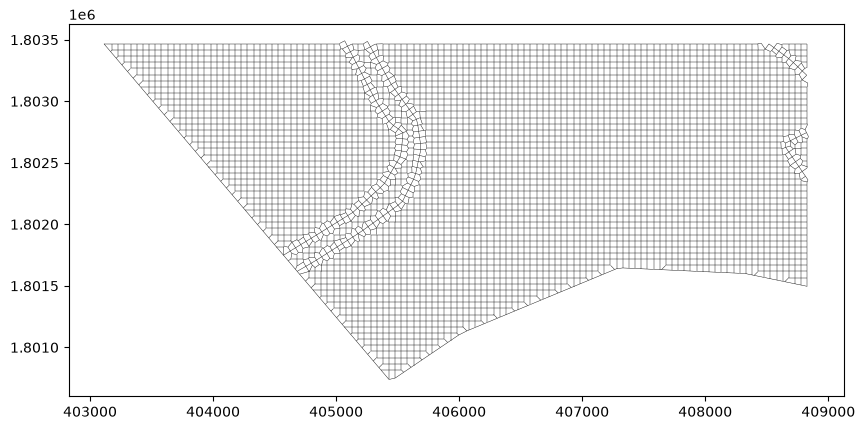

In [17]:
b = ds.bounds
sub = ds.crop(bbox=(b[0], b[1], (b[0]+b[2])/2, (b[1]+b[3])/2))
print('faces after crop:', sub.n_face, 'of', ds.n_face)
sub.plot_outline()


### 9g. Round-trip through UGRID NetCDF — `to_file()` / `to_xarray()`

`to_file(..., driver='ugrid')` writes the mesh to the CF/UGRID NetCDF convention — the lossless lingua franca every tool in the stack reads back. We write it, re-read it, and confirm the topology survived. `to_xarray()` hands the same content to the xarray ecosystem in memory.

In [18]:
import tempfile
out = Path(tempfile.mkdtemp()) / 'roundtrip.nc'
ds.to_file(out, driver="ugrid")
back = UgridDataset.read_file(out, driver="ugrid")
print('re-read nodes/faces:', back.n_node, back.n_face)
ds.to_xarray()

re-read nodes/faces: 21520 19407


<xarray.Dataset> Size: 2MB
Dimensions:            (mesh2d_scalar: 1, mesh2d_nNodes: 21520,
                        mesh2d_nFaces: 19407, mesh2d_nMaxFaceNodes: 8,
                        n_face: 19407)
Dimensions without coordinates: mesh2d_scalar, mesh2d_nNodes, mesh2d_nFaces,
                                mesh2d_nMaxFaceNodes, n_face
Data variables:
    mesh2d             (mesh2d_scalar) int32 4B 0
    mesh2d_node_x      (mesh2d_nNodes) float64 172kB 4.085e+05 ... 4.146e+05
    mesh2d_node_y      (mesh2d_nNodes) float64 172kB 1.807e+06 ... 1.8e+06
    mesh2d_face_nodes  (mesh2d_nFaces, mesh2d_nMaxFaceNodes) int64 1MB 1 ... ...
    material           (n_face) float64 155kB 7.0 7.0 7.0 7.0 ... 5.0 5.0 5.0
    manning_n          (n_face) float64 155kB 0.06 0.06 0.06 ... 0.05 0.05 0.05
    node_z             (mesh2d_nNodes) float64 172kB 951.6 951.6 ... 940.8 957.1
Attributes:
    Conventions:  CF-1.8 UGRID-1.0

### A note on writing back

`to_file(..., driver='ugrid')` above succeeds because UGRID NetCDF stores arbitrary polygons. Writing this mesh to `2dm` instead would raise `FileFormatNotSupportedError` — 2DM only defines element keywords for 3-, 4- and 6-node faces, and this mesh has 5-node polygons. The driver refuses rather than silently dropping them; pick a format whose element table can hold your topology.

## 10. Takeaway

The `srh2d` driver reads a three-file SRH-2D case from its `.srhgeom`, merging the roughness from the `.srhmat`, into a single real-world `UgridDataset`. Its mixed element types gate a few triangle-only operations (`circumcenters`) but everything topology-general — vectorise, boundary, components, adjacency, clip, UGRID round-trip — works at full scale.